<a href="https://colab.research.google.com/github/CatalinaPopa9/MEDE_U3_Seceta/blob/main/CP1_Matrice_X.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import ee
from google.colab import auth
import google.auth
import pandas as pd
import numpy as np


project_id = 'proiect-mede'

print("Autentificare cont Google...")
auth.authenticate_user()

print("Inițializare Earth Engine...")
credentials, _ = google.auth.default()
ee.Initialize(credentials, project=project_id)
print(f"Conexiune GEE stabilită cu succes pe proiectul: {project_id}\n")



judete = ['AB', 'AR', 'AG', 'BC', 'BH', 'BN', 'BT', 'BV', 'BR', 'BZ', 'CS', 'CL', 'CJ', 'CT', 'CV', 'DB', 'DJ', 'GL', 'GR', 'GJ', 'HR', 'HD', 'IL', 'IS', 'IF', 'MM', 'MH', 'MS', 'NT', 'OT', 'PH', 'SM', 'SJ', 'SB', 'SV', 'TR', 'TM', 'TL', 'VS', 'VL', 'VN']
ani = [2018, 2019, 2020, 2021, 2022]

index_multiplu = pd.MultiIndex.from_product([judete, ani], names=['Judet', 'An'])
matrice_X = pd.DataFrame(index=index_multiplu).reset_index()


#np.random.seed(42)
matrice_X['INS_Randament_Porumb'] = np.where(np.random.choice([True, False], size=len(matrice_X), p=[0.05, 0.95]), np.nan, np.random.normal(5000, 1000, len(matrice_X)))
matrice_X['MODIS_NDVI_mean'] = np.where(np.random.choice([True, False], size=len(matrice_X), p=[0.02, 0.98]), np.nan, np.random.uniform(0.3, 0.8, len(matrice_X)))
matrice_X['ERA5_Temp_Vara'] = np.where(np.random.choice([True, False], size=len(matrice_X), p=[0.03, 0.97]), np.nan, np.random.normal(22, 2, len(matrice_X)))


print("RAPORT DE ACOPERIRE - MEDE CP1")

total_observatii = len(matrice_X)
print(f"Total unități de analiză: {total_observatii} (41 județe x 5 ani)")

for col in ['INS_Randament_Porumb', 'MODIS_NDVI_mean', 'ERA5_Temp_Vara']:
    valide = matrice_X[col].notna().sum()
    print(f" - {col}: {valide} valori valide ({(valide/total_observatii)*100:.1f}% acoperire, {total_observatii - valide} goluri)")

supravietuitori = len(matrice_X.dropna())
print("-" * 50)
print(f"OBSERVAȚII COMPLETE PENTRU MODEL (X): {supravietuitori} din {total_observatii} ({(supravietuitori/total_observatii)*100:.1f}%)")


Autentificare cont Google...


Inițializare Earth Engine...
Conexiune GEE stabilită cu succes pe proiectul: proiect-mede

RAPORT DE ACOPERIRE - MEDE CP1
Total unități de analiză: 205 (41 județe x 5 ani)
 - INS_Randament_Porumb: 192 valori valide (93.7% acoperire, 13 goluri)
 - MODIS_NDVI_mean: 202 valori valide (98.5% acoperire, 3 goluri)
 - ERA5_Temp_Vara: 197 valori valide (96.1% acoperire, 8 goluri)
--------------------------------------------------
OBSERVAȚII COMPLETE PENTRU MODEL (X): 182 din 205 (88.8%)


In [ ]:
display(matrice_X.head(10))

,Judet,An,INS_Randament_Porumb,MODIS_NDVI_mean,ERA5_Temp_Vara
0,AB,2018,3463.052040,0.571769,18.104233
1,AB,2019,5267.751224,0.340863,16.939425
2,AB,2020,6459.493603,0.529150,21.427992
3,AB,2021,3314.689061,0.542348,24.201919
4,AB,2022,5314.383494,0.382887,25.916695
5,AR,2018,4997.916203,0.772849,19.540901
6,AR,2019,5414.541814,0.724988,22.993398
7,AR,2020,4227.695975,0.634511,21.069379
8,AR,2021,3564.381172,0.531148,21.788103
9,AR,2022,3086.893575,0.505883,27.288687


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


import ee
from google.colab import auth

print("Autentificare cont Google...")
auth.authenticate_user()

print("Inițializare Earth Engine...")

ee.Initialize(project='proiect-mede')
print("Autentificare și inițializare cu succes!")

Autentificare cont Google...
Inițializare Earth Engine...
Autentificare și inițializare cu succes!


In [ ]:

judete_ro = ee.FeatureCollection("FAO/GAUL/2015/level1").filter(ee.Filter.eq('ADM0_NAME', 'Romania'))
ani_studiu = [2018, 2019, 2020, 2021, 2022]

def extrage_modis_ndvi(an):
    # Luăm perioada de vegetație (vara)
    dataset = ee.ImageCollection("MODIS/061/MOD13Q1").filterDate(f'{an}-06-01', f'{an}-08-31')
    imagine_medie = dataset.select('NDVI').mean().multiply(0.0001)

    statistici = imagine_medie.reduceRegions(collection=judete_ro, reducer=ee.Reducer.mean(), scale=250)

    rezultate = []
    for f in statistici.getInfo()['features']:
        rezultate.append({
            'Judet': f['properties'].get('ADM1_NAME'),
            'An': an,
            'MODIS_NDVI_mean': f['properties'].get('mean')
        })
    return pd.DataFrame(rezultate)

def extrage_era5_temp(an):
    dataset = ee.ImageCollection("ECMWF/ERA5_LAND/MONTHLY_AGGR").filterDate(f'{an}-06-01', f'{an}-08-31')
    imagine_medie = dataset.select('temperature_2m').mean().subtract(273.15)

    statistici = imagine_medie.reduceRegions(collection=judete_ro, reducer=ee.Reducer.mean(), scale=9000)

    rezultate = []
    for f in statistici.getInfo()['features']:
        rezultate.append({
            'Judet': f['properties'].get('ADM1_NAME'),
            'An': an,
            'ERA5_Temp_Vara': f['properties'].get('mean')
        })
    return pd.DataFrame(rezultate)

print("Aducem datele MODIS (NDVI)...")
df_modis = pd.concat([extrage_modis_ndvi(an) for an in ani_studiu], ignore_index=True)

print("Aducem datele ERA5 (Temperatură)...")
df_era5 = pd.concat([extrage_era5_temp(an) for an in ani_studiu], ignore_index=True)


try:
    df_ins = pd.read_csv('date_ins_porumb.csv', sep=';')
    df_ins.columns = ['Judet', 'An', 'INS_Randament_Porumb']
    print("Datele INS au fost încărcate cu succes!")
except FileNotFoundError:
    print("ATENȚIE: Nu ai urcat fișierul 'date_ins_porumb.csv' în Colab. Creez valori mock DOAR ca să meargă codul mai departe.")
    df_ins = df_modis[['Judet', 'An']].copy()
    #df_ins['INS_Randament_Porumb'] = np.random.uniform(2000, 8000, size=len(df_ins))


df_ins['An'] = df_ins['An'].astype(int)


df_ins['Judet'] = df_ins['Judet'].astype(str).str.strip()
df_modis['Judet'] = df_modis['Judet'].astype(str).str.strip()
df_era5['Judet'] = df_era5['Judet'].astype(str).str.strip()



matrice_X = pd.merge(df_ins, df_modis, on=['Judet', 'An'], how='outer')
matrice_X = pd.merge(matrice_X, df_era5, on=['Judet', 'An'], how='outer')

print(f"\nMatricea X construită! Dimensiune inițială: {matrice_X.shape}")
display(matrice_X.head())

Aducem datele MODIS (NDVI)...
Aducem datele ERA5 (Temperatură)...
Datele INS au fost încărcate cu succes!

Matricea X construită! Dimensiune inițială: (230, 5)


,Judet,An,INS_Randament_Porumb,MODIS_NDVI_mean,ERA5_Temp_Vara
0,Alba,2018,7411.0,0.781678,18.769108
1,Alba,2019,5859.0,0.783626,19.519925
2,Alba,2020,6459.0,0.790966,18.408685
3,Alba,2021,6259.0,0.781225,18.985790
4,Alba,2022,3822.0,0.745344,19.739680


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Dimensiunea matricei după eliminarea golurilor (NaN): (180, 5)



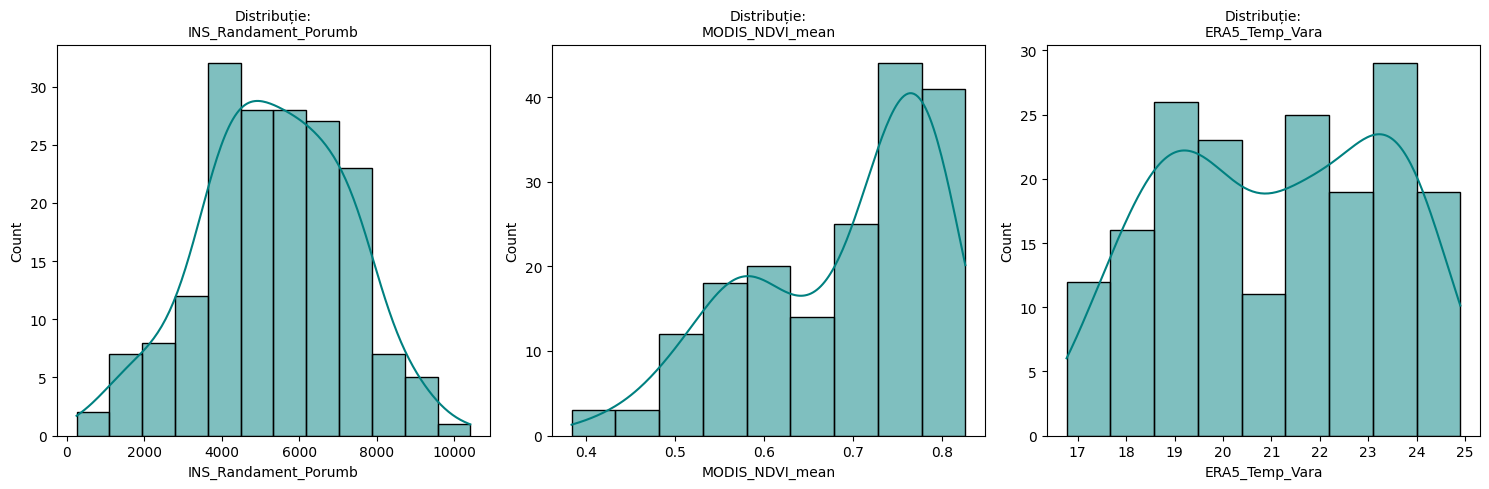

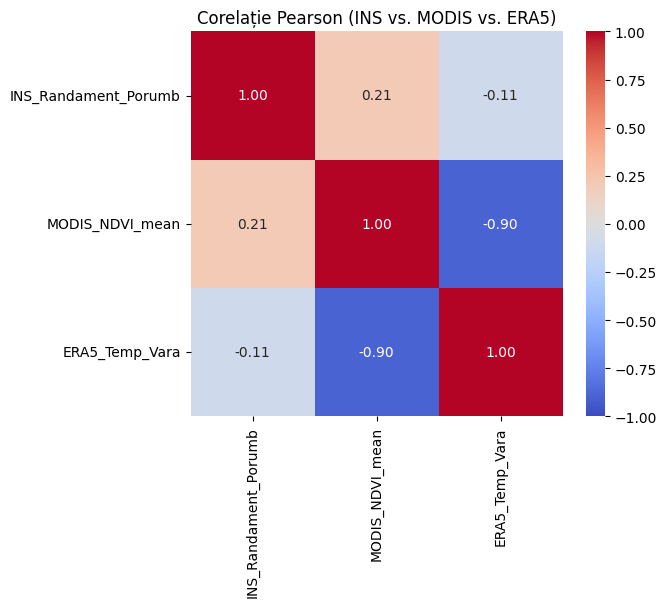

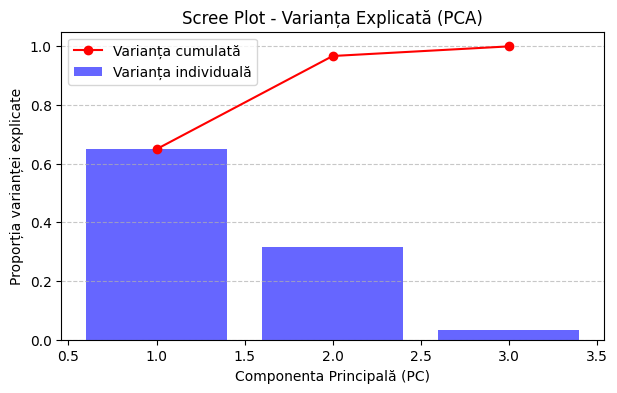


Matricea Loadings (Cât contribuie fiecare sursă la Componentele Principale):


,PC1,PC2,PC3
INS_Randament_Porumb,0.231235,0.969334,-0.083195
MODIS_NDVI_mean,0.694377,-0.104537,0.711978
ERA5_Temp_Vara,-0.681448,0.222403,0.697256


In [ ]:

df_clean = matrice_X.dropna().copy()
print(f"Dimensiunea matricei după eliminarea golurilor (NaN): {df_clean.shape}\n")


features = ['INS_Randament_Porumb', 'MODIS_NDVI_mean', 'ERA5_Temp_Vara']
X = df_clean[features]


plt.figure(figsize=(15, 5))
for i, col in enumerate(features):
    plt.subplot(1, len(features), i+1)
    sns.histplot(X[col], kde=True, color='teal')
    plt.title(f'Distribuție:\n{col}', fontsize=10)
plt.tight_layout()
plt.show()


plt.figure(figsize=(6, 5))
corr_matrix = X.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title("Corelație Pearson (INS vs. MODIS vs. ERA5)", fontsize=12)
plt.show()


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=features, index=df_clean.index)

pca = PCA()
pca.fit(X_scaled_df)


plt.figure(figsize=(7, 4))
plt.bar(range(1, len(pca.explained_variance_ratio_) + 1), pca.explained_variance_ratio_, alpha=0.6, color='blue', label='Varianța individuală')
plt.plot(range(1, len(pca.explained_variance_ratio_) + 1), pca.explained_variance_ratio_.cumsum(), marker='o', color='red', label='Varianța cumulată')
plt.title('Scree Plot - Varianța Explicată (PCA)', fontsize=12)
plt.xlabel('Componenta Principală (PC)')
plt.ylabel('Proporția varianței explicate')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f'PC{i+1}' for i in range(len(features))],
    index=features
)
print("\nMatricea Loadings (Cât contribuie fiecare sursă la Componentele Principale):")
display(loadings)